## Summary Statistics / Data Exploration

output tables, distributions, etc...

In [53]:
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from paths import DERIVED, FIGURES

con = duckdb.connect(str(DERIVED / 'congress.duckdb'))
colors = {'Democrat': '#1f4e9c', 'Republican': '#c8102e'}
colors2 = {'Democrat': '#1f4e9c', 'Republican': '#c8102e', 'Other': '#F5D547', 'Missing': '#ECE5F0'}


In [54]:
con.sql('DESCRIBE everything_but_speeches').df()[['column_name', 'column_type']]

,column_name,column_type
0,speech_id,BIGINT
1,chamber,VARCHAR
2,date,TIMESTAMP
3,number_within_file,BIGINT
4,speaker,VARCHAR
5,first_name,VARCHAR
6,last_name,VARCHAR
7,state,VARCHAR
8,gender,VARCHAR
9,line_start,BIGINT


How many speeches are there, by party? 

In [24]:
summary = con.sql('''
SELECT party_group, count(*) AS count, SUM(word_count) AS words, AVG(word_count) AS avg_length, MEDIAN(word_count) AS med_length
FROM everything_but_speeches
GROUP BY party_group
ORDER BY count DESC
''')
display(summary)

party_groupVARCHAR,countBIGINT,wordsHUGEINT,avg_lengthDOUBLE,med_lengthDOUBLE
Democrat,6998540,853067172,121.89216207951944,24.0
Republican,6180581,691681952,111.91212476626389,23.0
NULL,4084629,290503751,71.12120856018993,13.0
Other,132134,15520146,117.45762634900935,21.0


About 7 million democratic speeches, about 6 million republican speeches, and 4 million that are missing a party group. The speeches missing a party are meaningfully shorter (median length of 13 words, average length around 71). 

Missing Party Over time

In [23]:
missing = con.sql('''
SELECT congress,
       COUNT(*) as rows,
       COUNT(*) - COUNT(party) as missing_party_count,
       ROUND(100.0 * (COUNT(*) - COUNT(party)) / COUNT(*), 2) AS missing_share
FROM everything_but_speeches
GROUP BY congress
ORDER BY missing_share DESC
''').df()
display(missing)

missing['year'] = 1789 + 2 * (missing['congress'] - 1)



,congress,rows,missing_party_count,missing_share
0,110,212386,79204,37.29
1,111,179268,66718,37.22
2,109,186708,67202,35.99
3,108,194544,68880,35.41
4,107,178667,62252,34.84
...,...,...,...,...
64,74,247172,43567,17.63
65,82,261703,44777,17.11
66,72,237071,40097,16.91
67,61,279720,45199,16.16


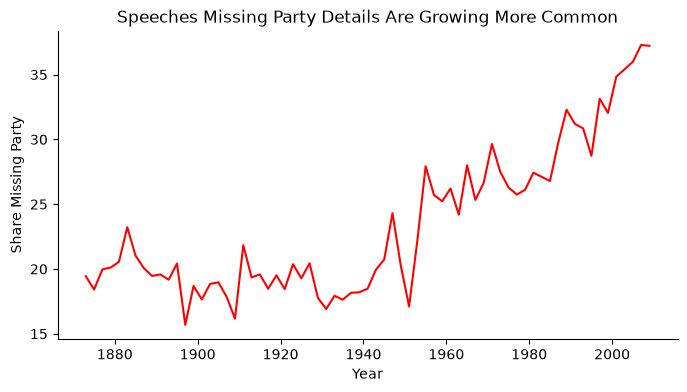

In [19]:
fig, ax = plt.subplots(figsize=(8, 4))

sns.lineplot(
    data=missing,
    x='year',
    y='missing_share',
    color = 'red',
    ax=ax
)
ax.set(
    xlabel = 'Year', 
    ylabel = 'Share Missing Party',
    title = 'Speeches Missing Party Details Are Growing More Common'
)
ax.spines[['top', 'right']].set_visible(False) # drop the box lines, as in lecture

fig.savefig(FIGURES / 'missing_rates.png')

,congress,party_group,count,words,avg_length,med_length,year
1,43,Missing,23187,1367732.0,58.987019,20.0,1873
2,43,Republican,69967,7326227.0,104.709749,26.0,1873
3,43,Democrat,24287,2683872.0,110.506526,23.0,1873
4,44,Missing,21127,1045625.0,49.492356,18.0,1875
5,44,Republican,49801,5077719.0,101.960182,24.0,1875
...,...,...,...,...,...,...,...
267,110,Republican,52749,14515049.0,275.172022,71.0,2007
268,110,Missing,79204,6766599.0,85.432541,14.0,2007
270,111,Missing,66718,6133647.0,91.933916,15.0,2009
271,111,Republican,46223,13124396.0,283.936482,104.0,2009


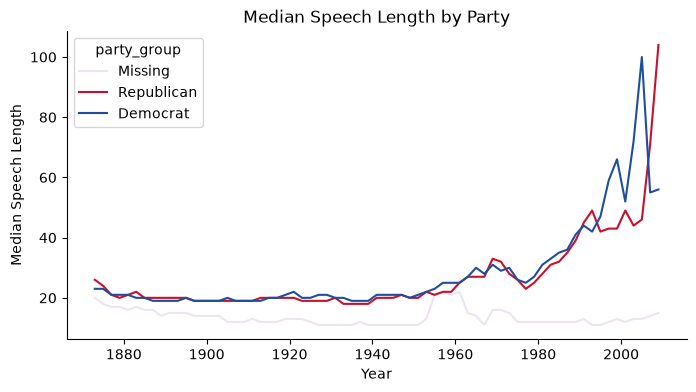

In [34]:
summary2 = con.sql('''
SELECT congress, party_group, count(*) AS count, SUM(word_count) AS words, AVG(word_count) AS avg_length, MEDIAN(word_count) AS med_length
FROM everything_but_speeches
GROUP BY party_group, congress
ORDER BY congress
''').df()
summary2['year'] = 1789 + 2 * (summary2['congress'] - 1)
summary2 = summary2.loc[summary2['party_group'] != 'Other']
summary2['party_group'] = summary2['party_group'].fillna('Missing')
display(summary2)

fig, ax = plt.subplots(figsize=(8, 4))

sns.lineplot(
    data=summary2,
    x='year',
    y='med_length',
    hue = 'party_group',
    palette = colors2,
    ax=ax
)
ax.set(
    xlabel = 'Year', 
    ylabel = 'Median Speech Length',
    title = 'Median Speech Length by Party'
)
ax.spines[['top', 'right']].set_visible(False) # drop the box lines, as in lecture

fig.savefig(FIGURES / 'party_speech_length.png')

Gender differences over time. 

,congress,party_group,rows,female_rows,female_share,year
0,43,Republican,69789,19.0,0.000272,1873
1,43,Other,1857,0.0,0.000000,1873
2,43,Missing,4897,10.0,0.002042,1873
3,43,Democrat,24220,13.0,0.000537,1873
4,44,Republican,49734,8.0,0.000161,1875
...,...,...,...,...,...,...
268,110,Republican,52706,4299.0,0.081566,2007
269,111,Republican,46195,4054.0,0.087758,2009
270,111,Missing,14459,2203.0,0.152362,2009
271,111,Democrat,65553,13900.0,0.212042,2009


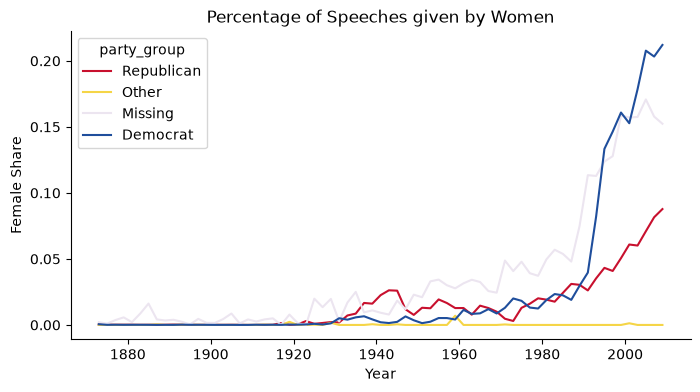

In [55]:
gender = con.sql('''
SELECT congress, party_group,
       COUNT(*) AS rows,
       COUNT_IF(gender = 'F') AS female_rows,
       female_rows / rows AS female_share
FROM everything_but_speeches
WHERE gender IN ('M', 'F')
GROUP BY congress, party_group
ORDER BY congress
''').df()
gender['year'] = 1789 + 2 * (gender['congress'] - 1)
gender['party_group'] = gender['party_group'].fillna('Missing')
display(gender)

fig, ax = plt.subplots(figsize=(8, 4))

sns.lineplot(
    data=gender,
    x='year',
    y='female_share',
    hue = 'party_group',
    palette = colors2,
    ax=ax
)
ax.set(
    xlabel = 'Year', 
    ylabel = 'Female Share',
    title = 'Percentage of Speeches given by Women'
)
ax.spines[['top', 'right']].set_visible(False) # drop the box lines, as in lecture

fig.savefig(FIGURES / 'female_share.png')


In [56]:
con.close()